In [4]:
%pylab inline
import os
import gc
import matplotlib
import numpy as np
import astropy.io.fits as pyfits
import astropy.table as astTable
import catutil as utilities
import pltutil
import treecorr

Populating the interactive namespace from numpy and matplotlib


In [16]:
datDir='wrkDir/s19/s19-pre/psf_test_from_wentao/rhoTest/'
datDir2='wrkDir/s19/s19-pre/psf_test_from_wentao/sizeCor/'
datDir3='wrkDir/s19/s19-pre/psf_test_from_wentao/regions/'
pltDir='wrkDir/s19/s19-1/anaCat_newS19Mask_fdeltacut/plot/psfTest/'

NSIDE = 1024
ORDERING = NESTED in fits file
INDXSCHM = IMPLICIT
NSIDE = 1024
ORDERING = NESTED in fits file
INDXSCHM = IMPLICIT
NSIDE = 1024
ORDERING = NESTED in fits file
INDXSCHM = IMPLICIT
NSIDE = 1024
ORDERING = NESTED in fits file
INDXSCHM = IMPLICIT
NSIDE = 1024
ORDERING = NESTED in fits file
INDXSCHM = IMPLICIT
NSIDE = 1024
ORDERING = NESTED in fits file
INDXSCHM = IMPLICIT
NSIDE = 1024
ORDERING = NESTED in fits file
INDXSCHM = IMPLICIT
NSIDE = 1024
ORDERING = NESTED in fits file
INDXSCHM = IMPLICIT
NSIDE = 1024
ORDERING = NESTED in fits file
INDXSCHM = IMPLICIT
NSIDE = 1024
ORDERING = NESTED in fits file
INDXSCHM = IMPLICIT
NSIDE = 1024
ORDERING = NESTED in fits file
INDXSCHM = IMPLICIT
NSIDE = 1024
ORDERING = NESTED in fits file
INDXSCHM = IMPLICIT


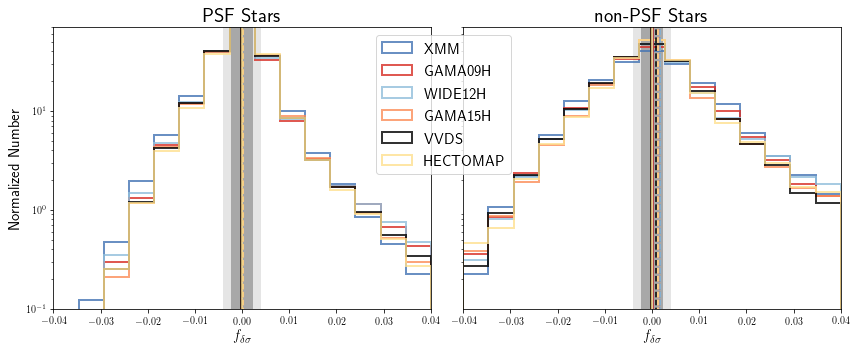

In [9]:
plt.close()
fig = plt.figure(figsize=(12,5))
fig.set_rasterized(True) 
nbins = 15
ip=0
figNList=['PSF Stars','non-PSF Stars']
for sname in ['psfstars','nonpsfstars']:
    ip+=1
    ax = fig.add_subplot(1,2,ip)
    ax.set_rasterized(True)
    ax.set_title(figNList[ip-1],fontsize=20)
    ax.fill_betweenx([0.0,80],[-0.0023,-0.0023],x2=0.0023,alpha=0.6,facecolor='grey')
    ax.fill_betweenx([0.0,80],[-0.004,-0.004],x2=0.004,alpha=0.2,facecolor='grey')
    ax.set_xlim(-0.04,0.04)
    ax.set_ylim(0.1,70.0)
    ax.set_yscale('log')
    if ip==1:
        ax.set_ylabel('Normalized Number',fontsize=15)
    else:
        ax.set_yticks(())
    ax.set_xlabel(r'$f_{\delta\sigma}$',fontsize=15)
    for fieldname in utilities.field_names:
        cc=pltutil.plot_colors[fieldname]
        fname=os.path.join(datDir2,'%s_sm-S19A-g15_%s.fits' %(fieldname,sname))
        data=pyfits.getdata(fname)
        mask=utilities.get_FDFC_flag(data,'wrkDir/database/s19a_fdfc_hp_contarea_izy-gt-5_trimmed_fd001.fits')
        data=data[mask]
        sstar=utilities.get_gal_size(data,'det')
        spsf= utilities.get_psf_size(data,'det')
        fd  = (spsf-sstar)/sstar
        ax.hist(fd,bins=nbins,range=(-0.04,0.04),histtype='step',facecolor='white',\
                 edgecolor=cc,linewidth=2.0,\
                 label=fieldname,density=True,alpha=0.8)
        ax.plot([np.median(fd),np.median(fd)],[0.0,70],color=cc,ls='-')
        ax.plot([np.mean(fd),np.mean(fd)],[0.0,70],color=cc,ls='--')
        del data,sstar,spsf,fd
        gc.collect()
plt.tight_layout()
ax.legend(loc='upper left',bbox_to_anchor=(-0.25, 0.5, 0.5, 0.5),fontsize=15)
fig.savefig(os.path.join(pltDir,'psf_fdelta_dis.eps'),rasterized=True,dpi=100)

NSIDE = 1024
ORDERING = NESTED in fits file
INDXSCHM = IMPLICIT
NSIDE = 1024
ORDERING = NESTED in fits file
INDXSCHM = IMPLICIT
NSIDE = 1024
ORDERING = NESTED in fits file
INDXSCHM = IMPLICIT
NSIDE = 1024
ORDERING = NESTED in fits file
INDXSCHM = IMPLICIT
NSIDE = 1024
ORDERING = NESTED in fits file
INDXSCHM = IMPLICIT
NSIDE = 1024
ORDERING = NESTED in fits file
INDXSCHM = IMPLICIT
NSIDE = 1024
ORDERING = NESTED in fits file
INDXSCHM = IMPLICIT
NSIDE = 1024
ORDERING = NESTED in fits file
INDXSCHM = IMPLICIT
NSIDE = 1024
ORDERING = NESTED in fits file
INDXSCHM = IMPLICIT
NSIDE = 1024
ORDERING = NESTED in fits file
INDXSCHM = IMPLICIT
NSIDE = 1024
ORDERING = NESTED in fits file
INDXSCHM = IMPLICIT
NSIDE = 1024
ORDERING = NESTED in fits file
INDXSCHM = IMPLICIT


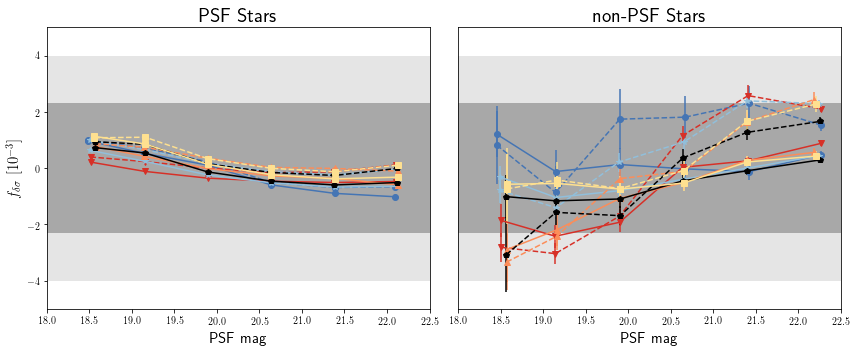

In [8]:
low   = 18.0
high  = 22.5
Nbin  = 6
step  = (high-low)/float(Nbin)

plt.close()
fig = plt.figure(figsize=(12,5))
fig.set_rasterized(True) 
nbins = 15
ip=0
figNList=['PSF Stars','non-PSF Stars']
for sname in ['psfstars','nonpsfstars']:
    ip+=1
    ax = fig.add_subplot(1,2,ip)
    ax.set_rasterized(True)
    ax.set_title(figNList[ip-1],fontsize=20)
    ax.fill_between([18,22.5],[-2.3,-2.3],[2.3,2.3],alpha=0.6,facecolor='grey',linewidth=0.0)
    ax.fill_between([18,22.5],[-4.,-4.],[4,4],alpha=0.2,facecolor='grey',linewidth=0.0)
    ax.set_xlim(18.0,22.5)
    ax.set_ylim(-5,5.)
    if ip==1:
        ax.set_ylabel(r'$f_{\delta\sigma}~[10^{-3}]$',fontsize=15)
    else:
        ax.set_yticks(())
    ax.set_xlabel('PSF mag',fontsize=15)
    for fieldname in utilities.field_names:
        cc=pltutil.plot_colors[fieldname]
        fname=os.path.join(datDir2,'%s_sm-S19A-g15_%s.fits' %(fieldname,sname))
        data=pyfits.getdata(fname)
        mask=utilities.get_FDFC_flag(data,'wrkDir/database/s19a_fdfc_hp_contarea_izy-gt-5_trimmed_fd001.fits')
        data=data[mask]
        mag=data['i_psfflux_mag']
        sstar=utilities.get_gal_size(data,'det')
        spsf= utilities.get_psf_size(data,'det')
        fd  = (spsf-sstar)/sstar
        fd0   = np.zeros(6)
        fd1   = np.zeros(6)
        error0= np.zeros(6)
        error1= np.zeros(6)
        magbn = np.zeros(6)
        for iy in range(6):
            idxa = mag>=low+float(iy)*step
            idxb = mag<low+float(iy+1)*step
            idx  = idxa&idxb
            fdu=fd[idx]
            magu=mag[idx]
            magbn[iy] = np.nanmean(magu)
            nn=len(fdu)
            fd0[iy]=np.nanmean(fdu)*1e3
            error0[iy]=np.std(fdu)*1e3/np.sqrt(nn)
            fd1[iy]=np.nanmedian(fdu)*1e3
            error1[iy]=np.percentile(fdu,16)*1e3/np.sqrt(nn)
        
        ax.errorbar(magbn,fd0,error0,ls='--',color=pltutil.plot_colors[fieldname],\
                    marker=pltutil.plot_fmt[fieldname],linewidth=1.5)
        ax.errorbar(magbn,fd1,error1,ls='-',color=pltutil.plot_colors[fieldname],label=fieldname,\
                    marker=pltutil.plot_fmt[fieldname],linewidth=1.5)
        del data,sstar,spsf,fd,fd0,fd1,error0,error1,magu,fdu
        gc.collect()
plt.tight_layout()
#ax.legend(loc='upper left',bbox_to_anchor=(-0.25, 0.5, 0.5, 0.5),fontsize=15)
fig.savefig(os.path.join(pltDir,'psf_fdelta_mag.eps'),rasterized=True,dpi=100)

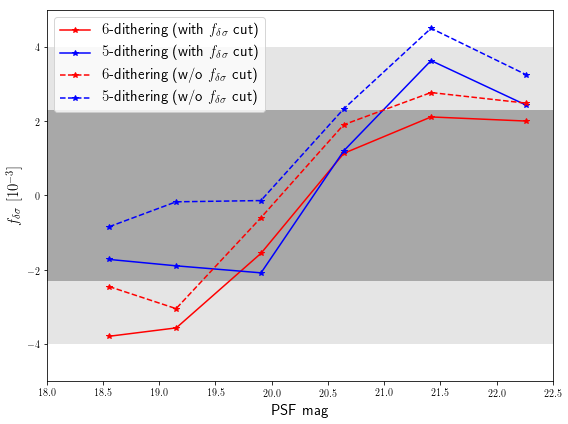

In [41]:
low   = 18.0
high  = 22.5
Nbin  = 6
step  = (high-low)/float(Nbin)

plt.close()
fig = plt.figure(figsize=(8,6))
fig.set_rasterized(True) 
ax1 = fig.add_subplot(1,1,1)
ax1.set_rasterized(True)
ax1.fill_between([18,22.5],[-2.3,-2.3],[2.3,2.3],alpha=0.6,facecolor='grey',linewidth=0.0)
ax1.fill_between([18,22.5],[-4.,-4.],[4,4],alpha=0.2,facecolor='grey',linewidth=0.0)
ax1.set_xlim(18.0,22.5)
ax1.set_ylim(-5,5.)
ax1.set_ylabel(r'$f_{\delta\sigma}~[10^{-3}]$',fontsize=15)
ax1.set_xlabel('PSF mag',fontsize=15)

nbins = 15
ip=0
lsList=['-','--']
nnList=[r'with $f_{\delta\sigma}$ cut',r'w/o $f_{\delta\sigma}$ cut']
ic=3
for pend in ['fcut','nofcut']:
    ax.set_xlabel('PSF mag',fontsize=15)
    for fieldname in ['WIDE12H']:#utilities.field_names:
        cc=pltutil.plot_colors[fieldname]
        fname='dither_%s.dat' %(pend)
        fname=os.path.join(datDir3,fname)
        ii,mag,fd0,fd1 = np.loadtxt(fname,unpack=True)
        mag=mag[ii==ic]
        fd0=fd0[ii==ic]*1e3
        fd1=fd1[ii==ic]*1e3
        ax1.errorbar(mag,fd1,ls=lsList[ip],color='red',label=r'$6$-dithering (%s)' %nnList[ip],\
                    marker=pltutil.plot_fmt[fieldname],linewidth=1.5)
        ax1.errorbar(mag,fd0,ls=lsList[ip],color='blue',label=r'$5$-dithering (%s)' %nnList[ip],\
                    marker=pltutil.plot_fmt[fieldname],linewidth=1.5)
        ip+=1
ax1.legend(loc='upper left',fontsize=15)
plt.tight_layout()
fig.savefig(os.path.join(pltDir,'psf_wide12h_dither_fdelta_mag2.eps'),rasterized=True,dpi=100)

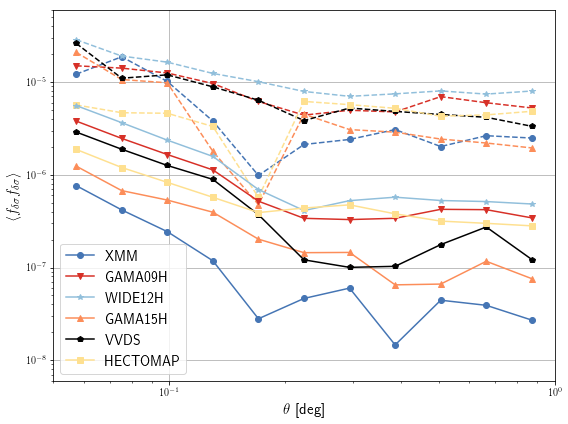

In [14]:
plt.close()
fig=plt.figure(figsize=(8,6))
ax=fig.add_subplot(1,1,1)
for fieldname in utilities.field_names:
    ofname=   os.path.join(datDir2,'%s_nonpsfstars-fdCor.csv' %fieldname)
    cor   =   treecorr.KKCorrelation(nbins=11,min_sep=0.05,max_sep=1.,sep_units='deg')
    if not os.path.isfile(ofname):
        fname=os.path.join(datDir2,'%s_sm-S19A-g15_nonpsfstars.fits' %fieldname)
        data=pyfits.getdata(fname)
        #mask=utilities.get_FDFC_flag(data,'wrkDir/database/s19a_fdfc_hp_contarea_izy-gt-5_trimmed_fd001.fits')
        #data=data[mask]
        ra,dec  =   utilities.get_radec(data)
        sstar=utilities.get_gal_size(data,'det')
        spsf=utilities.get_psf_size(data,'det')
        fd=(spsf-sstar)/sstar
        cat   =   treecorr.Catalog(k=fd,ra=ra,dec=dec,ra_units='deg',dec_units='deg')
        cor.process(cat)
        cor.write(ofname)
    else:
        cor.read(ofname)
    ax.plot(cor.rnom,cor.xi,marker=pltutil.plot_fmt[fieldname],ls='--',color=pltutil.plot_colors[fieldname])
        
for fieldname in utilities.field_names:
    ofname=   os.path.join(datDir2,'%s_psfstars-fdCor.csv' %fieldname)
    cor   =   treecorr.KKCorrelation(nbins=11,min_sep=0.05,max_sep=1.,sep_units='deg')
    if not os.path.isfile(ofname):
        fname=os.path.join(datDir2,'%s_sm-S19A-g15_psfstars.fits' %fieldname)
        data=pyfits.getdata(fname)
        #mask=utilities.get_FDFC_flag(data,'wrkDir/database/s19a_fdfc_hp_contarea_izy-gt-5_trimmed_fd001.fits')
        #data=data[mask]
        ra,dec  =   utilities.get_radec(data)
        sstar=utilities.get_gal_size(data,'det')
        spsf=utilities.get_psf_size(data,'det')
        fd=(spsf-sstar)/sstar
        cat   =   treecorr.Catalog(k=fd,ra=ra,dec=dec,ra_units='deg',dec_units='deg')
        cor.process(cat)
        cor.write(ofname)
    else:
        cor.read(ofname)
    ax.plot(cor.rnom,cor.xi,marker=pltutil.plot_fmt[fieldname],ls='-',color=pltutil.plot_colors[fieldname],label=fieldname)
    ax.set_xscale('log')
    ax.set_yscale('log')
    ax.set_ylim(6e-9,6e-5)
    ax.set_xlabel(r'$\mathrm{\theta}$ [deg]',fontsize=15)
    ax.set_ylabel(r'$\langle f_{\delta\sigma}f_{\delta\sigma} \rangle$',fontsize=15)
    ax.legend(loc='lower left',fontsize=14)
    plt.tight_layout()
ax.grid()
fig.savefig(os.path.join(pltDir,'psf_starsize_corr2.eps'))

In [ ]:
low   = 18.0
high  = 22.5
Nbin  = 6 
step  = (high-low)/float(Nbin)
data  = np.zeros((6,6))
data1 = np.zeros((6,6))
error = np.zeros((6,6))
error1= np.zeros((6,6))
magbn= np.zeros(6)
for ix in range(1):
ix =1
if ix == 0:
  fd,fw,mg = np.loadtxt(prefix+'W06_fdelta_fwhm_magi_scatter_'+torf+'.dat',unpack=True)
  d1 = fd
if ix == 1:
  fd,fw,mg = np.loadtxt(prefix+'W03_fdelta_fwhm_magi_scatter_'+torf+'.dat',unpack=True)
  d2 = fd
if ix == 2:
  fd,fw,mg = np.loadtxt(prefix+'WIDE12H_fdelta_fwhm_magi_scatter_'+torf+'.dat',unpack=True)
  d3 = fd
if ix == 3:
  fd,fw,mg = np.loadtxt(prefix+'GAMA15H_fdelta_fwhm_magi_scatter_'+torf+'.dat',unpack=True)
  d4 = fd
if ix == 4:
  fd,fw,mg = np.loadtxt(prefix+'W05_fdelta_fwhm_magi_scatter_'+torf+'.dat',unpack=True)
  d5 = fd
if ix == 5:
  fd,fw,mg = np.loadtxt(prefix+'W02_fdelta_fwhm_magi_scatter_'+torf+'.dat',unpack=True)
  d6 = fd

for iy in range(6):
  idxa = mg>=low+float(iy)*step
  idxb = mg<low+float(iy+1)*step
  idx  = idxa&idxb
  magbn[iy] = low+float(iy)*step+0.5*step
  #for iz in range(6):
  data[ix,iy]=np.nanmean(fd[idx])
  data1[ix,iy]=np.nanmedian(fd[idx])
  #error[ix,iy]=np.percentile(fd[idx],84)
  error[ix,iy]=np.std(fd[idx])
  error1[ix,iy]=np.percentile(fd[idx],16)
  #print magbn[iy],len(fd[idx]) 
if torf =='true':
 figurename = 'S19a PSF stars'
if torf =='false':
 figurename = 'S19a non-PSF stars high dense region'
#temp1 = data1[0,:]+error[0,:]
#temp2 = data1[0,:]-error1[0,:]
#print np.shape(temp1)
#print temp1
#print temp2
#plt.errorbar(magbn,data1[0,:],yerr=error[0,:],fmt='r^',elinewidth=2.5)
"""
plt.plot(magbn,data1[0,:],'r^')
plt.plot(magbn,data[0,:],'r^')
plt.plot(magbn,data[0,:],'r--',linewidth=2.5)
plt.plot(magbn,data1[0,:],'r-',label='W06(HECTOMAP) ',linewidth=2.5)
""" 
plt.plot(magbn,data1[1,:],'gs')
plt.plot(magbn,data[1,:],'gs')
plt.plot(magbn,data[1,:],'g--',linewidth=2.5)
plt.plot(magbn,data1[1,:],'g-',label='W03(GAMA09H)',linewidth=2.5)

""" 
plt.plot(magbn,data1[2,:],'bs')
plt.plot(magbn,data[2,:],'bs')
plt.plot(magbn,data[2,:],'b--',linewidth=2.5)
plt.plot(magbn,data1[2,:],'b-',label='WIDE12H',linewidth=2.5)

plt.plot(magbn,data1[3,:],'yd')
plt.plot(magbn,data[3,:],'yd')
plt.plot(magbn,data[3,:],'y--',linewidth=2.5)
plt.plot(magbn,data1[3,:],'y-',label='GAMA15H',linewidth=2.5)

plt.plot(magbn,data1[4,:],'k*')
plt.plot(magbn,data[4,:],'k*')
plt.plot(magbn,data[4,:],'k--',linewidth=2.5)
plt.plot(magbn,data1[4,:],'k-',label='W05(VVDS)',linewidth=2.5)

plt.plot(magbn,data1[5,:],'+',color='cyan')
plt.plot(magbn,data[5,:],'+',color='cyan')
plt.plot(magbn,data[5,:],'--',linewidth=2.5)
plt.plot(magbn,data1[5,:],'-',color='cyan',label='W02(XMM)',linewidth=2.5)
""" 
plt.fill_between([18,22.5],[-0.004/2.0,-0.004/2.0],[0.004/2.0,0.004/2.0],alpha=0.5,\
facecolor='grey',linewidth=0.0)
plt.plot([18.0,22.5],[0.004,0.004],'k--',linewidth=2)
plt.plot([18.0,22.5],[-0.004,-0.004],'k--',linewidth=2,label='S16A requirements')
plt.xlim(18.0,22.5)
plt.ylim(-0.014,0.014)
plt.xlabel('i psf mag')
plt.ylabel(r'f$\delta\sigma$')
plt.title(figurename)
plt.legend(loc='lower right')
plt.show()


NSIDE = 1024
ORDERING = NESTED in fits file
INDXSCHM = IMPLICIT
NSIDE = 1024
ORDERING = NESTED in fits file
INDXSCHM = IMPLICIT
NSIDE = 1024
ORDERING = NESTED in fits file
INDXSCHM = IMPLICIT
NSIDE = 1024
ORDERING = NESTED in fits file
INDXSCHM = IMPLICIT
NSIDE = 1024
ORDERING = NESTED in fits file
INDXSCHM = IMPLICIT
NSIDE = 1024
ORDERING = NESTED in fits file
INDXSCHM = IMPLICIT


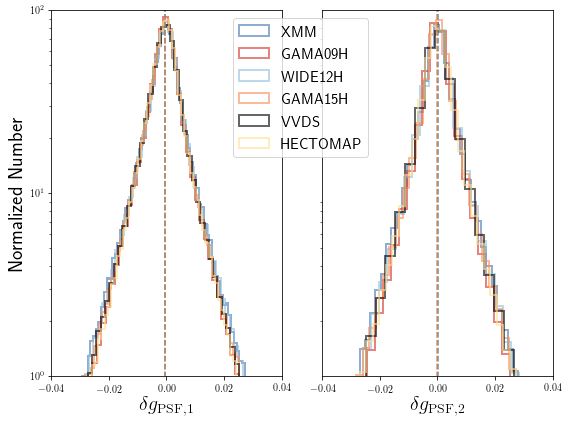

In [5]:
plt.close()

fig=plt.figure(figsize=(8,6))
fig.set_rasterized(True) 

ax1=fig.add_subplot(1,2,1)
ax1.set_rasterized(True)
ax1.set_xlim(-0.04,0.04)
ax1.set_ylim(1.0,100.0)
ax1.set_xlabel(r'$\delta g_{\rm{PSF},1}$',fontsize=20)
ax1.set_yscale('log')
ax1.set_ylabel('Normalized Number',fontsize=20)

ax2=fig.add_subplot(1,2,2)
ax2.set_rasterized(True)
ax2.set_xlim(-0.04,0.04)
ax2.set_ylim(1.0,100.0)
ax2.set_yscale('log')
ax2.set_xlabel(r'$\delta g_{\rm{PSF},2}$',fontsize=20)

for fieldname in utilities.field_names:
    fname=os.path.join(datDir2,'%s_sm-S19A-g15_psfstars.fits' %fieldname)
    data=pyfits.getdata(fname)
    mask=utilities.get_FDFC_flag(data,'wrkDir/database/s19a_fdfc_hp_contarea_izy-gt-5_trimmed_fd001.fits')
    data=data[mask]
    es1,es2=utilities.get_gal_ellip(data)
    ep1,ep2=utilities.get_psf_ellip(data)
    d1=es1-ep1
    d10=es2-ep2
    nbins = 100
    ax1.hist(d1,200,histtype='step',facecolor='white',edgecolor=pltutil.plot_colors[fieldname],\
             linewidth=2.,label=fieldname,density=True,alpha=0.6)
    ax1.plot([np.mean(d1),np.mean(d1)],[0.0,170],ls='--',\
             color=pltutil.plot_colors[fieldname],alpha=0.4)
    ax2.hist(d10,nbins,histtype='step',facecolor='white',edgecolor=pltutil.plot_colors[fieldname],\
             linewidth=2.,label=fieldname,density=True,alpha=0.6)
    ax2.plot([np.mean(d10),np.mean(d10)],[0.0,170],ls='--',\
             color=pltutil.plot_colors[fieldname],alpha=0.4)
plt.tight_layout()
ax2.legend(loc='upper left',bbox_to_anchor=(-0.42, 0.5, 0.5, 0.5),fontsize=15)
ax2.set_yticks(())
fig.savefig(os.path.join(pltDir,'psf_dshape_dis2.eps'),rasterized=True,dpi=100)